<a href="https://colab.research.google.com/github/AR1679/DSC212/blob/main/Dsc_karate_club.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration | communities |      Q
    0     |      1      |  0.000
    1     |      2      |  0.371
    2     |      3      |  0.392
    3     |      4      |  0.393
    4     |      5      |  0.379
    5     |      6      |  0.368
    6     |      7      |  0.352

Final communities (member IDs):
  1: [9, 10, 15, 16, 19, 21, 23, 27, 30, 31, 33, 34]
  2: [1, 5, 6, 7, 11, 12, 17]
  3: [24, 25, 26, 28]
  4: [29]
  5: [32]
  6: [2, 18, 20, 22]
  7: [3, 4, 8, 13, 14]


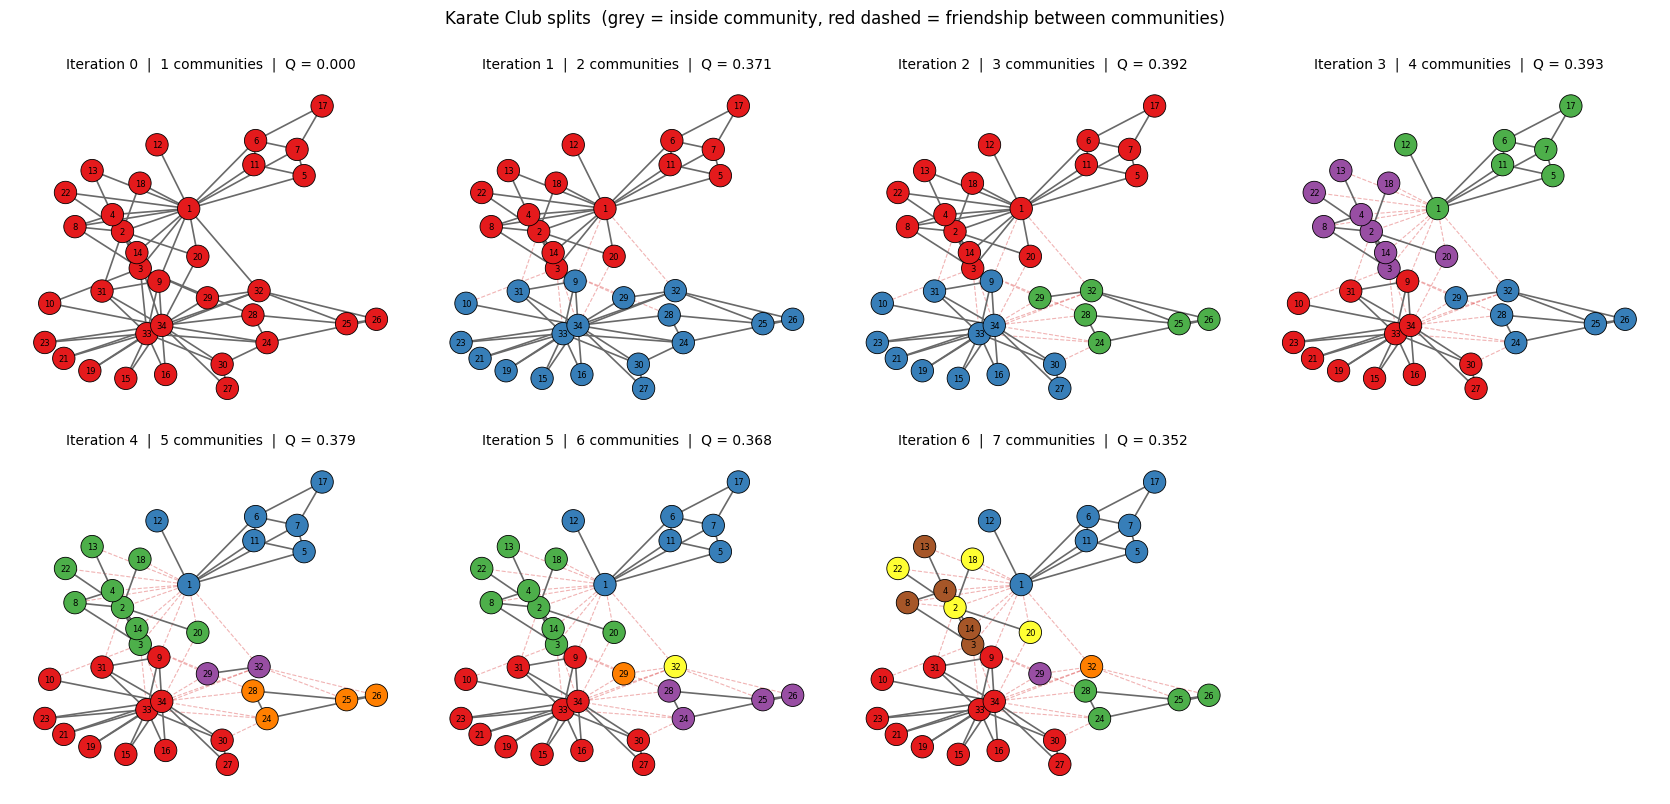

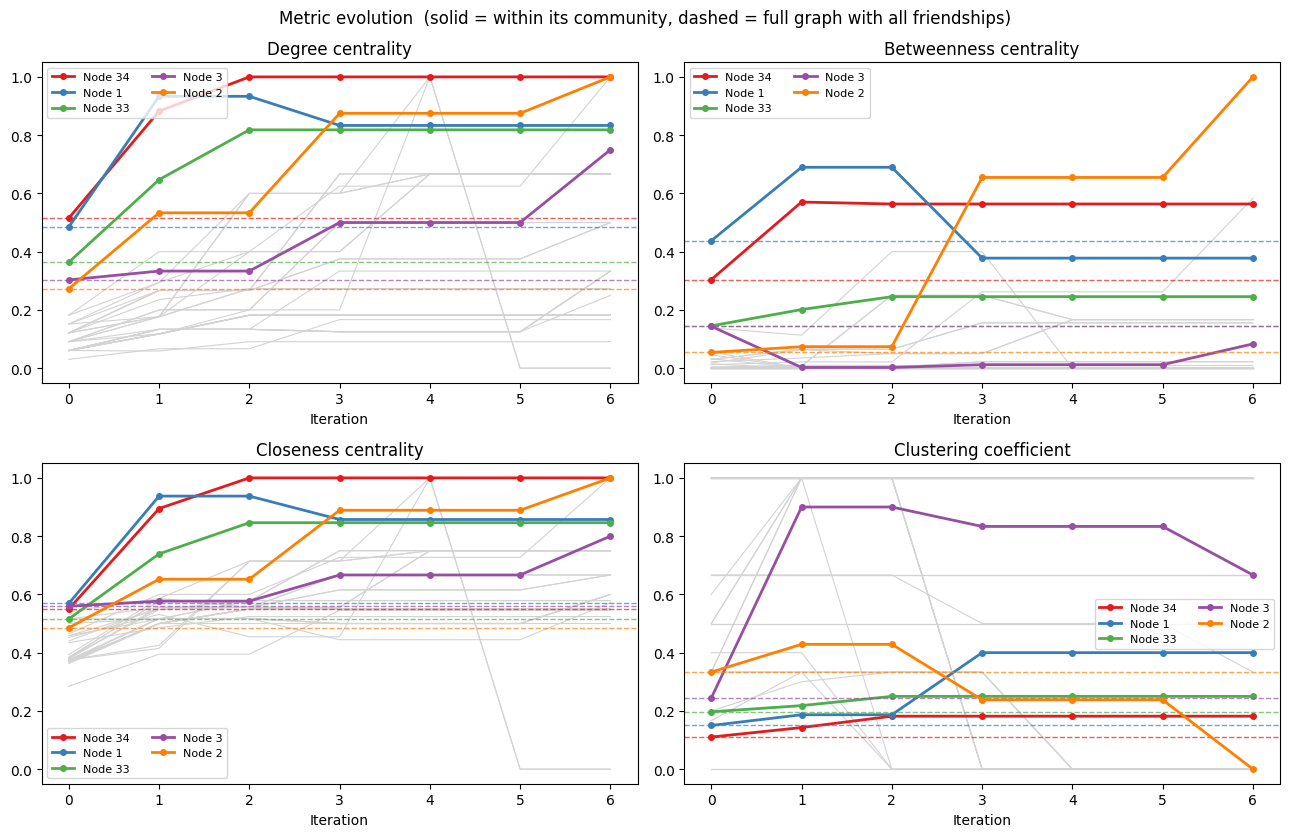

    Degree centrality  Betweenness centrality  Closeness centrality  Clustering coefficient  avg_rank
1               0.485                   0.438                 0.569                   0.150       1.3
34              0.515                   0.304                 0.550                   0.110       2.0
3               0.303                   0.144                 0.559                   0.244       3.3
33              0.364                   0.145                 0.516                   0.197       4.0
32              0.182                   0.138                 0.541                   0.200       5.2
2               0.273                   0.054                 0.485                   0.333       7.0


In [2]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# %% 1. Graph and modularity matrix  B = A - k k^T / 2m
G = nx.Graph(nx.karate_club_graph())
for u, v in G.edges:
    G[u][v].pop('weight', None)                       # unweighted, as in the handout
n = G.number_of_nodes()
nodes = list(range(n))
pos = nx.spring_layout(G, seed=42)                    # same layout in every picture

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
m = k.sum() / 2
B = A - np.outer(k, k) / (2 * m)

# %% 2. Best split of one group (Newman's B^(C) with diagonal correction)
def split_group(C):
    BC = B[np.ix_(C, C)].copy()
    BC -= np.diag(BC.sum(axis=1))
    vals, vecs = np.linalg.eigh(BC)
    for j in (-1, -2, -3):                            # leading eigenvector, then 2nd/3rd if signs are all equal
        if len(C) + j < 0:
            break
        s = np.where(vecs[:, j] > 0, 1, -1)
        if abs(s.sum()) == len(C):
            continue
        dQ = s @ BC @ s / (4 * m)
        return dQ, [C[i] for i in range(len(C)) if s[i] == 1], [C[i] for i in range(len(C)) if s[i] == -1]
    return None

# %% 3. Split until TARGET communities
TARGET = 7
communities = [nodes]
snapshots = [[list(nodes)]]
while len(communities) < TARGET:
    options = [(split_group(C), C) for C in communities if len(C) > 1]
    options = [(r, C) for r, C in options if r is not None]
    if not options:
        break
    (dQ, plus, minus), C = max(options, key=lambda x: x[0][0])
    communities.remove(C)
    communities += [plus, minus]
    snapshots.append([sorted(c) for c in communities])

print("Iteration | communities |      Q")
for i, comms in enumerate(snapshots):
    Q = nx.community.modularity(G, [set(c) for c in comms])
    print(f"{i:^9} | {len(comms):^11} | {Q:6.3f}")
print("\nFinal communities (member IDs):")
for j, c in enumerate(snapshots[-1], 1):
    print(f"  {j}: {[v + 1 for v in sorted(c)]}")

# %% 4. Draw all iterations in one figure
#    grey solid = friendships inside a community, red dashed = friendships between communities
def draw(comms, ax, title):
    label = {v: idx for idx, c in enumerate(comms) for v in c}
    inside = [(u, v) for u, v in G.edges if label[u] == label[v]]
    between = [(u, v) for u, v in G.edges if label[u] != label[v]]
    nx.draw_networkx_edges(G, pos, edgelist=between, ax=ax, style="dashed", edge_color="tab:red", alpha=0.35, width=0.8)
    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, edge_color="dimgray", width=1.2)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[label[v] for v in nodes], cmap=plt.cm.Set1,
                           vmin=0, vmax=8, node_size=260, edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, labels={v: v + 1 for v in nodes}, font_size=6, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

cols = 4
rows = int(np.ceil(len(snapshots) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4 * rows))
axes = np.ravel(axes)
for ax in axes:
    ax.axis("off")
for i, comms in enumerate(snapshots):
    Q = nx.community.modularity(G, [set(c) for c in comms])
    draw(comms, axes[i], f"Iteration {i}  |  {len(comms)} communities  |  Q = {Q:.3f}")
fig.suptitle("Karate Club splits  (grey = inside community, red dashed = friendship between communities)", y=1.0)
plt.tight_layout()
plt.show()

# %% 5. Metrics after each split
#    "full graph": all friendships, so it never changes.  "within community": each community on its own.
funcs = {"Degree centrality": nx.degree_centrality, "Betweenness centrality": nx.betweenness_centrality,
         "Closeness centrality": nx.closeness_centrality, "Clustering coefficient": nx.clustering}
full = {name: f(G) for name, f in funcs.items()}
within = {name: [] for name in funcs}
for comms in snapshots:
    for name, f in funcs.items():
        vals = {}
        for c in comms:
            if len(c) == 1:                       # a lone member has no friends inside its community
                vals[c[0]] = 0.0
            else:
                vals.update(f(G.subgraph(c)))
        within[name].append(vals)

# %% 6. Plot evolution: solid = within community, dashed = same node in the full graph
iters = list(range(len(snapshots)))
top = sorted(nodes, key=lambda v: -full['Degree centrality'][v])[:5]   # 5 best-connected members
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, name in zip(axes.ravel(), funcs):
    for v in nodes:
        if v not in top:
            ax.plot(iters, [within[name][i][v] for i in iters], color="lightgray", lw=0.8)
    for c, v in enumerate(top):
        col = plt.cm.Set1(c)
        ax.plot(iters, [within[name][i][v] for i in iters], "-o", color=col, lw=2, ms=4, label=f"Node {v + 1}")
        ax.axhline(full[name][v], color=col, ls="--", lw=1, alpha=0.7)
    ax.set_title(name)
    ax.set_xlabel("Iteration")
    ax.set_xticks(iters)
    ax.legend(fontsize=8, ncol=2)
fig.suptitle("Metric evolution  (solid = within its community, dashed = full graph with all friendships)")
plt.tight_layout()
plt.show()

# %% 7. Summary table: full-graph values of the most central nodes
import pandas as pd
df = pd.DataFrame({name: {v + 1: round(full[name][v], 3) for v in nodes} for name in funcs})
df["avg_rank"] = df.iloc[:, :3].rank(ascending=False).mean(axis=1).round(1)   # rank on the 3 centralities
print(df.sort_values("avg_rank").head(6).to_string())